# Estimating flood damage
**In this notebook a model is created which is able to detect houses area which was heavily affected by floods and mud floods during the late spring 2023 at the shoreline of Lake Kivu.**

Simon Rüegg · SDS320 · December 2026

---



## 1. Set up

Setup instructions and the required conda environment are described in the [README](README.md).\
To run the notebook without get the kernel crashing, following cell must be run so that GDAL and PROJ work as they should. 

In [1]:
import os, sys
env = sys.prefix
os.environ["PATH"] = os.path.join(env, "Library", "bin") + os.pathsep + os.environ["PATH"]
os.environ["GDAL_DATA"] = os.path.join(env, "Library", "share", "gdal")
os.environ["PROJ_DATA"] = os.path.join(env, "Library", "share", "proj")

In a next step all libraries in this notebook need ti be loaded. Also functions to merge and clip raster files later are loaded in this step

In [46]:
# Third-party libraries
import ee
import geemap
import geoai
import geopandas as gpd
import math
import matplotlib.cm as cm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
import shapely
from affine import Affine
from dotenv import load_dotenv
from lazyslide.metrics.segmentation import (
    get_instance_stats, precision, recall, f1_score, mean_iou, pq
)
from matplotlib.patches import Patch
from rasterio.enums import Resampling
from rasterio.mask import mask
from rasterio.plot import show
from rasterio.windows import Window, from_bounds
from scipy.interpolate import RBFInterpolator
from shapely.geometry import Polygon, mapping
from shapely.geometry import LineString
from shapely.geometry.polygon import orient
from shapely.affinity import affine_transform
from shapely.strtree import STRtree
from shapely.ops import unary_union

# Local modules
from functions.clip_tifs import clip_tifs
from functions.merge_tifs import merge_tifs

---
## 2. Data



### 2.1 Satellite imagery data

The data used for this project is from the Vantor's Open Data Program. Vantor provides there data from pre- and post disasters. To download the data a Vantor account is needed. This notebook works with the visual images. Vantor would also provide multispectral and panchromatic images from the same area and times.

In [3]:
# load the rasters
# the pre event tifs
rgb_pre_north = "../data/raw/raster/10300100E57BC400-visual_pre_north.tif" # pre event
rgb_pre_south = "../data/raw/raster/10300100E57BC400-visual_pre_south.tif" # pre event
rgb_post_north = "../data/raw/raster/1040010084614200-visual_post_north.tif" # post event
rgb_post_south = "../data/raw/raster/1040010084614200-visual_post_south.tif" # post event

Since the files not come as one file but in parts the different files need to be merged together.

In [4]:
# merge the files
rgb_pre = merge_tifs([rgb_pre_north, rgb_pre_south], "../data/processed/rgb_pre.tif") # pre event
rgb_post = merge_tifs([rgb_post_north, rgb_post_south], "../data/processed/rgb_post.tif") # post event

Skipping (already exists): ..\data\processed\rgb_pre.tif
Skipping (already exists): ..\data\processed\rgb_post.tif


Following code can be run to inspect the loaded and then merged rasters. It is important that the two rasters have the same CRS, bands and the same resolution to make the results meaningful.

In [7]:
with rasterio.open("../data/processed/rgb_pre.tif") as src:
    print("Visual RGB pre-event")
    print("--------------------")
    print(f"  {'Size (W × H)':<14} {src.width:,} × {src.height:,} px")
    print(f"  {'Bands':<14} {src.count}")
    print(f"  {'Data type':<14} {src.dtypes[0]}")
    print(f"  {'CRS':<14} {src.crs}")
    print(f"  {'Resolution':<14} {src.res[0]:.3f}, {src.res[1]:.3f}")
    print(f"  {'Bounds':<14} {src.bounds}")
    print(f"  {'NoData':<14} {src.nodata}")
    print()

with rasterio.open("../data/processed/rgb_post.tif") as src:
    print("Visual RGB post-event")
    print("---------------------")
    print(f"  {'Size (W × H)':<14} {src.width:,} × {src.height:,} px")
    print(f"  {'Bands':<14} {src.count}")
    print(f"  {'Data type':<14} {src.dtypes[0]}")
    print(f"  {'CRS':<14} {src.crs}")
    print(f"  {'Resolution':<14} {src.res[0]:.3f}, {src.res[1]:.3f}")
    print(f"  {'Bounds':<14} {src.bounds}")
    print(f"  {'NoData':<14} {src.nodata}")

Visual RGB pre-event
--------------------
  Size (W × H)   17,408 × 33,792 px
  Bands          3
  Data type      uint8
  CRS            EPSG:32735
  Resolution     0.305, 0.305
  Bounds         BoundingBox(left=709843.75, bottom=9774843.75, right=715156.25, top=9785156.25)
  NoData         None

Visual RGB post-event
---------------------
  Size (W × H)   17,408 × 33,792 px
  Bands          3
  Data type      uint8
  CRS            EPSG:32735
  Resolution     0.305, 0.305
  Bounds         BoundingBox(left=709843.75, bottom=9774843.75, right=715156.25, top=9785156.25)
  NoData         None


### 2.2 Buildings data

To let the train it needs to know where buildings stand. For the area at Lake Kivu there is no dataset which provides the outlines of the buildings. Google's Earth Engine provides a data set with buildings, but unfortunately the confidence level are low. Therefore, the building used to train the model are hand drawn by the author in QGIS.

In [ ]:
# read in the buildings
buildings = gpd.read_file("../GIS/buildings.gpkg")

---
## Data processing

To reduce runtime the the total area where the model later should run needs to be decreased. Also training and validation area need to be defined.


### 3.1 Select Area of Interest (AOI)

In this chapter the raster files get clipped into an AOI for the area that should be analysed for the damage. In addition, we clip AOI's for training and validation are selected. The training and the validation happen on the post-event image. The training area is approximately five times bigger than the Validation area. The model is later applied on the whole pre- and also post-event image.\
The AOI for the total AOI, training and validation set are drawn as polygons in QGIS as a GeoPackage file.

In [19]:
# reduce the size of the total tif area
tif_names = ["rgb_post.tif", "rgb_pre.tif"]

clip_tifs(
    tif_names,
    aoi_path="../GIS/aoi_total_area.gpkg",
    folder="../data/processed",
    suffix="_clipped"
)

clipping rgb_post.tif
clipping rgb_pre.tif


[WindowsPath('../data/processed/rgb_post_clipped.tif'),
 WindowsPath('../data/processed/rgb_pre_clipped.tif')]

In [24]:
tif_names = ["rgb_post_clipped.tif", "rgb_pre_clipped.tif"]

# clip training data aoi
clip_tifs(
    tif_names,
    aoi_path="../GIS/aoi_training.gpkg",
    folder="../data/processed",
    suffix="_training"
)

# clip validation data aoi
clip_tifs(
    tif_names,
    aoi_path="../GIS/aoi_validation.gpkg",
    folder="../data/processed",
    suffix="_validation"
)

clipping rgb_post_clipped.tif
clipping rgb_pre_clipped.tif
clipping rgb_post_clipped.tif
clipping rgb_pre_clipped.tif


[WindowsPath('../data/processed/rgb_post_clipped_validation.tif'),
 WindowsPath('../data/processed/rgb_pre_clipped_validation.tif')]

### 3.2 Prepare Building

Clipping the building layer into training and validation set. The buildings in the training area are used to train the model, while the buildings in the validation area are used to validate the model.

In [10]:
buildings = gpd.read_file("../GIS/buildings.gpkg")
train_aoi = gpd.read_file("../GIS/aoi_training.gpkg")
val_aoi = gpd.read_file("../GIS/aoi_validation.gpkg")

# CRS of the rasters (the labels must match the images)
with rasterio.open("../data/processed/rgb_post_clipped_training.tif") as src:
    train_crs = src.crs

with rasterio.open("../data/processed/rgb_post_clipped_validation.tif") as src:
    val_crs = src.crs

# Reproject everything to the raster CRS and clip to the true outlines
buildings_train = gpd.clip(buildings.to_crs(train_crs), train_aoi.to_crs(train_crs), keep_geom_type=True)
buildings_val = gpd.clip(buildings.to_crs(val_crs), val_aoi.to_crs(val_crs), keep_geom_type=True)

# Overview
print(f"  {'Buildings AOI':<20} {len(buildings):,}")
print(f"  {'Buildings training':<20} {len(buildings_train):,}")
print(f"  {'Buildings validation':<20} {len(buildings_val):,}")

# Save
buildings_train.to_file("../data/processed/buildings_train.gpkg", driver="GPKG")
buildings_val.to_file("../data/processed/buildings_val.gpkg", driver="GPKG")

  Buildings AOI        1,232
  Buildings training   717
  Buildings validation 292


## 4. Train the model

In this chapter the model to detect buildings on the images is trained. Before the model can get trained the images are prepared in tiles. During the training the model makes already an internal validation.

### 4.1 Prepare tiles
In a first step the building layer needs to be transformed in a raster mask. 

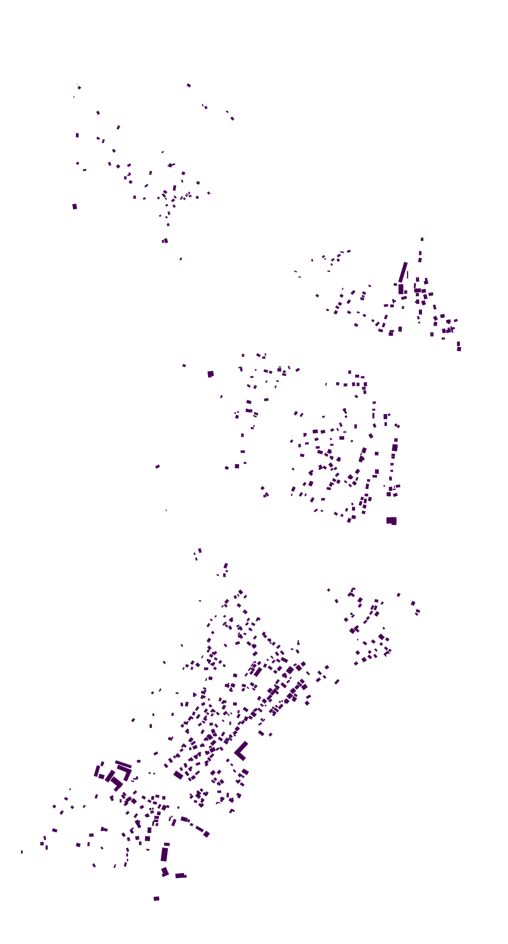

In [ ]:
# Transfer reference data from vector to raster
geoai.vector_to_raster(
    "../data/processed/buildings_train.gpkg",
    "../data/processed/buildings_training.tif",
    reference_raster = "../data/processed/rgb_post_clippped_training.tif"
)

geoai.view_image("../data/processed/buildings_training.tif", figsize=(12,12))

Generated: 197, With features: 197: 100%|██████████| 544/544 [00:10<00:00, 51.94it/s]


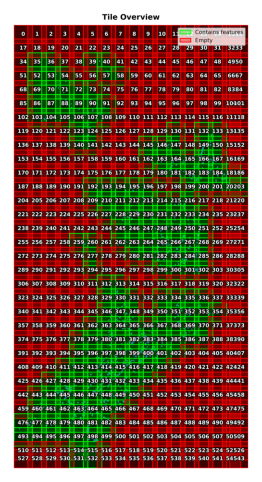

In [ ]:
# workaround the get_map function wich proably is called in the geoai.
if not hasattr(cm, "get_cmap"):
    cm.get_cmap = plt.get_cmap

tiles = geoai.export_geotiff_tiles(
    in_raster="../data/processed/rgb_post_clipped_training.tif",
    out_folder="../data/training/rgb",
    in_class_data="../data/processed/buildings_train.gpkg",
    tile_size=256,
    stride=192,
    buffer_radius=0,
    skip_empty_tiles=True,
    create_overview=True,
    quiet=True,
)

geoai.view_image("../data/training/rgb/overview.png", figsize=(6, 6))


In [14]:
stats = geoai.export_geotiff_tiles_batch(
    images_folder="../data/training/rgb/images/",
    masks_folder="../data/training/rgb/labels/",
    output_folder="../data/training/rgb/matched_files",
    tile_size=256,
    stride=128,
    class_value_field="class",
    skip_empty_tiles=True,
    match_by_name=True,
)
print(f"Images processed: {stats['processed_pairs']}")
print(f"Total tiles generated: {stats['total_tiles']}")
print(f"Tiles with features: {stats['tiles_with_features']}")

Processing image pairs: 100%|██████████| 197/197 [00:17<00:00, 11.00it/s]

Images processed: 197
Total tiles generated: 197
Tiles with features: 197


Based in the tiles the model later trains just on tiles where buildings are present as well. In total the training AOI contains 192 tiles with buildings.


**In the next step the model is trained.**
> Note: Training takes a long time and is skipped by default.\
> To retrain the model, set `RUN_TRAINING = True` in the configuration cell.

In [ ]:
# Training: images + labels from the export
# Takes some time. Set RUN_TRAINING = True to retrain the model
RUN_TRAINING = False

if RUN_TRAINING:
    geoai.train_instance_segmentation_model(
        images_dir="../data/training/rgb/images",
        labels_dir="../data/training/rgb/labels",
        output_dir="../models/rgb",
        num_classes=2,
        num_channels=3,
        batch_size=4,
        num_epochs=50,
        learning_rate=0.005,
        val_split=0.2,
        instance_labels=False,   # labels are binary, not per-house IDs
        visualize=True,
        verbose=True,
    )
else:
    print("Training skipped – using the existing model in ../models/rgb")

The results of the training are saved as .pth files. The quality of the training can be inspected with the history file. Within each epoch the training loss and validation loss should decrease while the IoU (Intersection of Union) should increase. The epochs for the training should be as large that the variable are in a stable state.

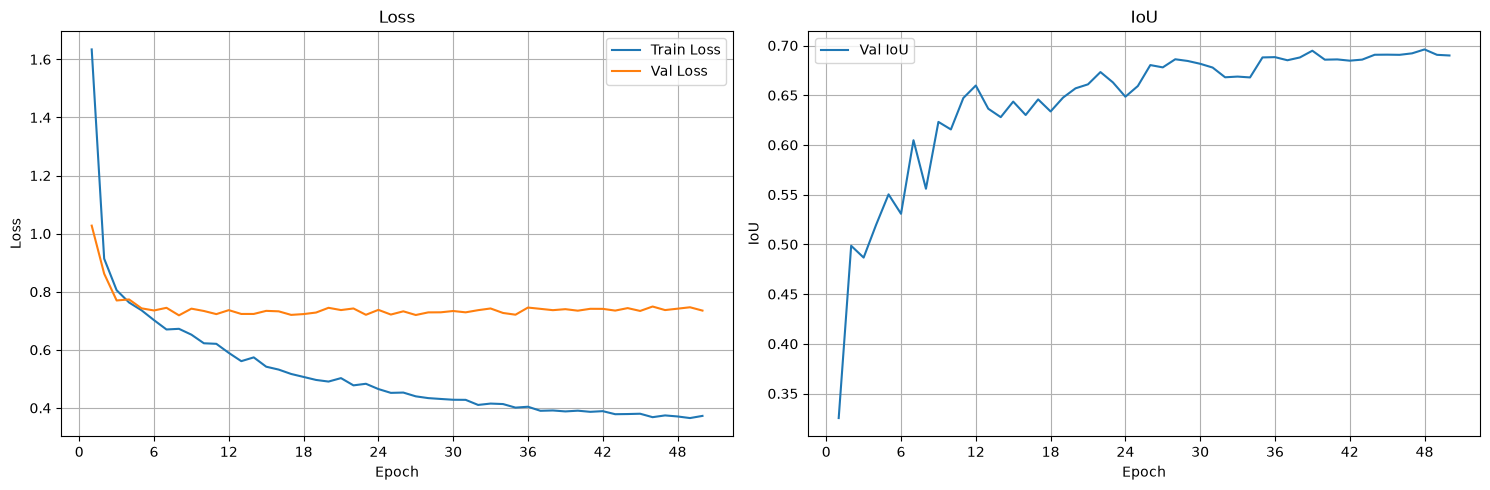

In [ ]:
# inspect training history
geoai.plot_performance_metrics(
    history_path="../models/rgb/training_history.pth",
    figsize=(15, 5),
    verbose=True,
); # ; makes that the table of the values is not printed.

## 5. Validation of the model

Despite the model already do an internal validation during training it is important to do a separate validation. The validation should be done in a different area than where the training was done.\
In a second step post-processing methods are used to get explored which then can be used to improve the final model results.  

### 5.1 Validation of the model

The model is used on the validation area, which was not used for training. The validation area for this project is located approximately 4 kilometre north of the training area in a similar environment which was also affected by mud floods.

In [ ]:
# validation
# !Note! Takes some time to run (~5-10')
geoai.instance_segmentation(
    input_path="../data/processed/rgb_post_clipped_validation.tif",
    output_path="../data/validation/rgb/prediction.tif",
    model_path="../models/rgb/best_model.pth",
    num_classes=2,
    num_channels=3,
    window_size=256,
    overlap=128,
    confidence_threshold=0.5,
    batch_size=4,
);

221it [07:04,  1.92s/it]


Since the geoai function gives back a raster file and the building are as polygons the modelled buildings raster must be transformed into a polygon file.

In [22]:
# transform to vector
geoai.raster_to_vector(
    "../data/validation/rgb/prediction.tif",
    "../data/validation/rgb/prediction.gpkg",
);

Key metrics of the validation. With a IoU threshold of 0.5. The metrics improve with a lower IoU threshold.

In [26]:
pred = gpd.read_file("../data/validation/rgb/prediction.gpkg")
gt = gpd.read_file("../data/processed/buildings_val.gpkg").to_crs(pred.crs)

#  metrics
stats = get_instance_stats(gt, pred, iou_threshold=0.5)
print("precision", precision(stats))
print("recall   ", recall(stats))
print("F1       ", f1_score(stats))
print("mean IoU ", mean_iou(stats))
print("PQ       ", pq(stats))

precision 0.6816608996303923
recall    0.6746575342234706
F1        0.6781411309492508
mean IoU  0.7130515319396649
PQ        0.4835495758764681


### 5.2 Post-Processing

The modelled building layer show some tile artifacts where modelled buildings are split on tile lines. An increased overlap or bigger tile-size does not improve the modelled buildings and lead to more False Negative.\
The best way is to merge those buildings which are split artificially by the tiles. These splits appear in regular grid with mostly and gap of 3 pixels.\
The amount of buildings in the validation area will be decreased from 289 to 252 buildings.

In [28]:
# merge on the tiles split
RASTER   = "../data/validation/rgb/prediction.tif"
POLYS    = "../data/validation/rgb/prediction.gpkg"   # your vectorised prediction
STRIDE   = 128      # window_size - overlap
MAX_GAP  = 3        # px, your gaps are ~2
MIN_LEN  = 8        # px, min length the two polygons face each other
GRID_TOL = 3        # px, how close the seam must be to a multiple of STRIDE
ORIGIN   = (0, 0)   # (x0, y0) offset if your windows don't start at pixel 0

with rasterio.open(RASTER) as src:
    inv = ~src.transform
    gdf = gpd.read_file(POLYS).to_crs(src.crs)

# work in pixel coordinates so gaps and the grid are in pixels
coeffs = [inv.a, inv.b, inv.d, inv.e, inv.c, inv.f]
pix = [affine_transform(g, coeffs) for g in gdf.geometry]

def seam(a, b):
    r = MAX_GAP / 2 + 0.5
    inter = a.buffer(r).intersection(b.buffer(r))
    if inter.is_empty:
        return None
    x0, y0, x1, y1 = inter.bounds
    w, h = x1 - x0, y1 - y0
    if h >= MIN_LEN and w <= MAX_GAP + 1:      # vertical seam
        pos, axis = (x0 + x1) / 2 - ORIGIN[0], "v"
    elif w >= MIN_LEN and h <= MAX_GAP + 1:    # horizontal seam
        pos, axis = (y0 + y1) / 2 - ORIGIN[1], "h"
    else:
        return None
    off = pos % STRIDE
    on_grid = min(off, STRIDE - off) <= GRID_TOL
    return axis, pos, on_grid, inter

# candidate pairs
tree = STRtree(pix)
parent = list(range(len(pix)))
def find(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]; i = parent[i]
    return i

bridges, positions = [], []
for i, a in enumerate(pix):
    for j in tree.query(a.buffer(MAX_GAP)):
        if j <= i or a.distance(pix[j]) > MAX_GAP:
            continue
        s = seam(a, pix[j])
        if s is None:
            continue
        axis, pos, on_grid, inter = s
        positions.append((axis, pos))
        if on_grid:
            parent[find(j)] = find(i)
            bridges.append(inter)

# merge groups (handles houses split into 3 parts)
groups = {}
for i in range(len(pix)):
    groups.setdefault(find(i), []).append(i)

merged = []
for members in groups.values():
    parts = [pix[k] for k in members]
    if len(parts) > 1:
        parts += [b for b in bridges if any(b.distance(pix[k]) < 1 for k in members)]
    merged.append(unary_union(parts))

# back to map coordinates
fwd = src.transform
back = [fwd.a, fwd.b, fwd.d, fwd.e, fwd.c, fwd.f]
out = gpd.GeoDataFrame(geometry=[affine_transform(g, back) for g in merged], crs=src.crs)
out.to_file("../data/validation/rgb/prediction_merged.gpkg")
print(len(gdf), "->", len(out), "polygons")


# add area
g = gpd.read_file("../data/validation/rgb/prediction_merged.gpkg")
g["area_m2"] = g.to_crs(g.estimate_utm_crs()).area
g.to_file("../data/validation/rgb/prediction_merged.gpkg", driver="GPKG")

289 -> 252 polygons


The merge of the tile split building improve the validation statistically and visual (shown below). The statistically improvements of the post-processing are compared in [section ]

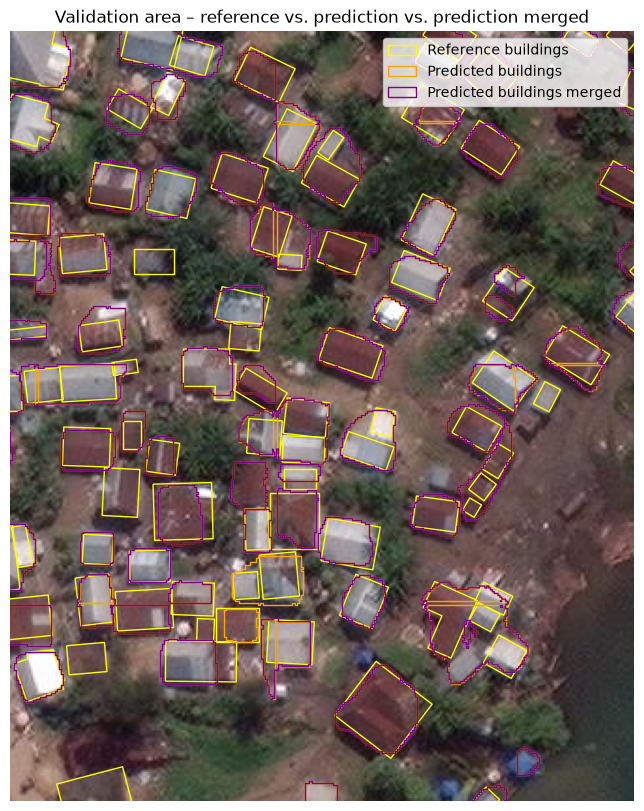

In [38]:
buildings_val = gpd.read_file("../data/processed/buildings_val.gpkg")
buildings_val_pred = gpd.read_file("../data/validation/rgb/prediction.gpkg")
buildings_val_pred_merged = gpd.read_file("../data/validation/rgb/prediction_merged.gpkg")

fig, ax = plt.subplots(figsize=(10, 10))

# Raster as background
with rasterio.open("../data/processed/rgb_post_validation.tif") as src:
    show(src, ax=ax)
    raster_crs = src.crs
    b = src.bounds

# Reference and predicted buildings as outlines
buildings_val.to_crs(raster_crs).boundary.plot(ax=ax, color="yellow", linewidth=1)
buildings_val_pred.to_crs(raster_crs).boundary.plot(ax=ax, color="orange", linewidth=1)
buildings_val_pred_merged.to_crs(raster_crs).boundary.plot(ax=ax, color="purple", linewidth=1)

# Zoom: section as a share of the full extent (0 = left/bottom, 1 = right/top)
x_start, x_end = 0.30, 0.50
y_start, y_end = 0.20, 0.40
ax.set_xlim(b.left + x_start * (b.right - b.left), b.left + x_end * (b.right - b.left))
ax.set_ylim(b.bottom + y_start * (b.top - b.bottom), b.bottom + y_end * (b.top - b.bottom))

# Legend, title, layout
ax.legend(handles=[
    Patch(facecolor="none", edgecolor="yellow", label="Reference buildings"),
    Patch(facecolor="none", edgecolor="orange", label="Predicted buildings"),
    Patch(facecolor="none", edgecolor="purple", label="Predicted buildings merged")
], loc="upper right")
ax.set_title("Validation area – reference vs. prediction vs. prediction merged")
ax.set_axis_off()
plt.show()

Some artifacts of the tile could not be removed. The model faces difficulties to detect False Positives in the Lake and at the borderline of the Area of Interest. Firstly inspect the edges of the AOI and then check which object will get removed by the filter

In [68]:
# Find Orientation of the AOI's angle
pred_merged = gpd.read_file("../data/validation/rgb/prediction_merged.gpkg")
val_aoi = gpd.read_file("../GIS/aoi_validation.gpkg").to_crs(pred_merged.crs)

aoi_poly = orient(val_aoi.union_all(), sign=1.0)   # sort vertices counter-clockwise
coords = list(aoi_poly.exterior.coords)

# Outward direction of each edge as compass bearing: 0° = north, 90° = east, 180° = south, 270° = west
for i, ((x1, y1), (x2, y2)) in enumerate(zip(coords[:-1], coords[1:])):
    bearing = math.degrees(math.atan2(y2 - y1, -(x2 - x1))) % 360
    print(f"  Edge {i}: {bearing:6.1f}°")


  Edge 0:  119.4°
  Edge 1:  143.9°
  Edge 2:  123.8°
  Edge 3:   86.1°
  Edge 4:   19.9°
  Edge 5:  294.1°
  Edge 6:  189.2°


  Selected edges         5
  Predictions before     252
  Removed at edge        4
  Predictions after      248


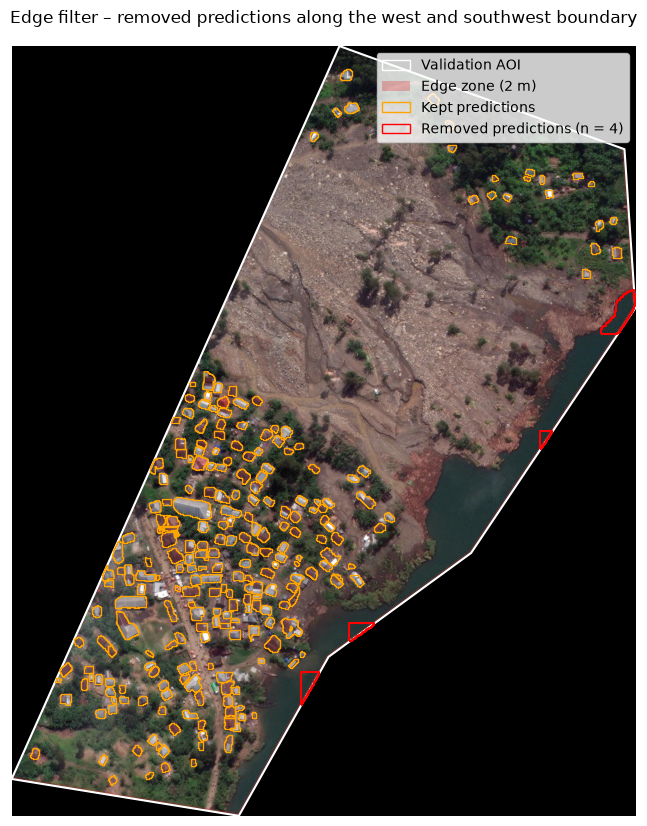

In [ ]:
edge_width = 2                    # set two 2 to not remove True Positives (meters)
bearing_min, bearing_max = 45, 285   # west + southwest;

selected_edges = []
for (x1, y1), (x2, y2) in zip(coords[:-1], coords[1:]):
    bearing = math.degrees(math.atan2(y2 - y1, -(x2 - x1))) % 360
    if bearing_min <= bearing_max:
        in_range = bearing_min <= bearing <= bearing_max
    else:  
        in_range = bearing >= bearing_min or bearing <= bearing_max
    if in_range:
        selected_edges.append(LineString([(x1, y1), (x2, y2)]))

# Strip inside the AOI along the selected edges
edge_zone = gpd.GeoSeries(selected_edges, crs=val_aoi.crs).union_all().buffer(edge_width).intersection(aoi_poly)

# Remove predictions that touch the strip
on_edge = pred_merged.intersects(edge_zone)
pred_filtered = pred_merged[~on_edge]

print(f"  {'Selected edges':<22} {len(selected_edges)}")
print(f"  {'Predictions before':<22} {len(pred_merged):,}")
print(f"  {'Removed at edge':<22} {on_edge.sum():,}")
print(f"  {'Predictions after':<22} {len(pred_filtered):,}")


fig, ax = plt.subplots(figsize=(10, 10))

# Raster as background
with rasterio.open("../data/processed/rgb_post_clipped_validation.tif") as src:
    show(src, ax=ax)
    raster_crs = src.crs

# AOI outline and edge zone
val_aoi.to_crs(raster_crs).boundary.plot(ax=ax, color="white", linewidth=1.5)
gpd.GeoSeries([edge_zone], crs=val_aoi.crs).to_crs(raster_crs).plot(ax=ax, color="tab:red", alpha=0.3)

# Kept and removed predictions
pred_filtered.to_crs(raster_crs).boundary.plot(ax=ax, color="orange", linewidth=1)
pred_merged[on_edge].to_crs(raster_crs).boundary.plot(ax=ax, color="red", linewidth=1.5)

# Legend, title, layout
ax.legend(handles=[
    Patch(facecolor="none", edgecolor="white", label="Validation AOI"),
    Patch(facecolor="tab:red", alpha=0.3, label=f"Edge zone ({edge_width} m)"),
    Patch(facecolor="none", edgecolor="orange", label="Kept predictions"),
    Patch(facecolor="none", edgecolor="red", label=f"Removed predictions (n = {on_edge.sum()})"),
], loc="upper right")
ax.set_title("Edge filter – removed predictions along the west and southwest boundary")
ax.set_axis_off()
plt.show()

In [65]:
# safe file with removed False Positives
pred_filtered.to_file("../data/validation/rgb/prediction_merged_rm_edge.gpkg", driver="GPKG")

# safe edge zone
gpd.GeoDataFrame(geometry=[edge_zone], crs=val_aoi.crs).to_file(
    "../data/validation/rgb/edge_zone.gpkg", driver="GPKG"
)

#### 5.2.1 Improvement of the post-processing

In [70]:
pred = gpd.read_file("../data/validation/rgb/prediction.gpkg")
pred_merged = gpd.read_file("../data/validation/rgb/prediction_merged.gpkg").to_crs(pred.crs)
pred_merged_rm_edge = gpd.read_file("../data/validation/rgb/prediction_merged_rm_edge.gpkg").to_crs(pred.crs)
gt = gpd.read_file("../data/processed/buildings_val.gpkg").to_crs(pred.crs)

# Metrics before and after post-processing
stats = get_instance_stats(gt, pred, iou_threshold=0.5)
stats_merged = get_instance_stats(gt, pred_merged, iou_threshold=0.5)
stats_merged_rm_edge = get_instance_stats(gt, pred_merged_rm_edge, iou_threshold=0.5)

results = pd.DataFrame(
    {
        "Raw prediction": [precision(stats), recall(stats), f1_score(stats), mean_iou(stats), pq(stats)],
        "Post-processed (Step 1)": [precision(stats_merged), recall(stats_merged), f1_score(stats_merged),
                           mean_iou(stats_merged), pq(stats_merged)],
        "Post-processed (Step 1+2)": [precision(stats_merged_rm_edge), recall(stats_merged_rm_edge), f1_score(stats_merged_rm_edge),
                           mean_iou(stats_merged_rm_edge), pq(stats_merged_rm_edge)],                       
    },
    index=["Precision", "Recall", "F1 score", "Mean IoU", "PQ"],
)
results["Improvement of Merging"] = results["Post-processed (Step 1)"] - results["Raw prediction"]
results["Improvement of Merging & Remove FP in the Lake"] = results["Post-processed (Step 1+2)"] - results["Raw prediction"]

results.style.format({
    "Raw prediction": "{:.3f}",
    "Post-processed": "{:.3f}",
    "Improvement of Merging": "{:+.3f}",
    "Improvement of Merging & Remove FP in the Lake": "{:+.3f}",
})

,Raw prediction,Post-processed (Step 1),Post-processed (Step 1+2),Improvement of Merging,Improvement of Merging & Remove FP in the Lake
Precision,0.682,0.793651,0.806452,+0.112,+0.125
Recall,0.675,0.684932,0.684932,+0.010,+0.010
F1 score,0.678,0.735294,0.740741,+0.057,+0.063
Mean IoU,0.713,0.716764,0.716764,+0.004,+0.004
PQ,0.484,0.527032,0.530936,+0.043,+0.047
